# 02 · Listings: Các cột mô tả chỗ ở

Listings là bảng trung tâm của bộ dữ liệu. Calendar và reviews đều nối vào nó, và phần lớn KPI sẽ được tính từ nó. Notebook này đi
qua bảng theo đúng thứ tự mà người viết QA cần: Cấu trúc bảng, các ô bị thiếu, kiểu dữ liệu, giá, các cột phân loại, sự thay đổi
giữa các mốc, và cuối cùng là thử gắn cờ.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

TEN_CAU_HINH = "london.yaml"   # Đổi file cấu hình ở đây nếu khảo sát thành phố/mốc khác.


def tim_thu_muc_du_an(thu_muc_bat_dau: Path) -> Path:
    """Đi ngược lên các thư mục cha cho tới khi gặp configs/<TEN_CAU_HINH>."""
    # Vòng lặp qua các thư mục cha (vài cấp), không phải qua dòng dữ liệu.
    for thu_muc in [thu_muc_bat_dau, *thu_muc_bat_dau.parents]:
        if (thu_muc / "configs" / TEN_CAU_HINH).is_file():
            return thu_muc

    raise FileNotFoundError(f"Không tìm thấy thư mục dự án chứa configs/{TEN_CAU_HINH}")


THU_MUC_DU_AN = tim_thu_muc_du_an(Path.cwd().resolve())

with (THU_MUC_DU_AN / "configs" / TEN_CAU_HINH).open("r", encoding="utf-8-sig") as f:
    cau_hinh = yaml.safe_load(f)

thanh_pho = cau_hinh["city"]
snapshots = [str(snapshot) for snapshot in cau_hinh["snapshots"]]   # YAML đọc ngày không nháy thành date
moc_gia = max(snapshots)   # Quy tắc của nhóm: chỉ mốc cuối được dùng giá
THU_MUC_RAW = THU_MUC_DU_AN / "data" / "raw" / thanh_pho
THU_MUC_PHAN_CONG = THU_MUC_DU_AN / "data" / "assignment"

phan_cong_listings = pd.read_csv(THU_MUC_PHAN_CONG / "listings.csv", dtype=str, keep_default_na=False)
phan_cong_reviews = pd.read_csv(THU_MUC_PHAN_CONG / "reviews.csv", dtype=str, keep_default_na=False)
phan_cong_vung = pd.read_csv(THU_MUC_PHAN_CONG / "areas.csv", dtype={"analysis_area": str}, keep_default_na=False)
cac_listing_id = set(phan_cong_listings["listing_id"])
cac_review_id = set(phan_cong_reviews["review_id"])

print("Thư mục dự án :", THU_MUC_DU_AN.name)
print("Thành phố     :", thanh_pho, "| tiền tệ:", cau_hinh["currency"])
print("Các mốc       :", snapshots, "| mốc dùng giá:", moc_gia)
print("Phân công     :", len(cac_listing_id), "listing,", len(cac_review_id), "review")

Thư mục dự án : 2627-LTXLDL-Airbnb-dse2049_7-nhom15
Thành phố     : london | tiền tệ: GBP
Các mốc       : ['2025-09-14', '2025-12-13', '2026-03-21', '2026-06-19'] | mốc dùng giá: 2026-06-19
Phân công     : 1000 listing, 5000 review


## 1. Đọc listings của bốn mốc

Ô dưới đây đọc toàn bộ file listings của thành phố (để so quy mô), rồi tách riêng 1.000 listing của nhóm. Mọi cột được giữ ở dạng
chuỗi nhờ `dtype=str` và `keep_default_na=False`. Nếu để pandas tự đoán kiểu, ID dài có thể bị đổi sang số thực và mất chữ số cuối.
Ngoài ra, ô trống và chữ `"None"` sẽ cùng bị đổi thành `NaN`, khiến ta không còn phân biệt được nguồn để trống hay nguồn ghi chữ None.

In [2]:
listings_thanh_pho: dict[str, pd.DataFrame] = {}
listings_nhom: dict[str, pd.DataFrame] = {}

# Vòng lặp qua từng mốc (4 lần), phép tính bên trong vẫn chạy trên cả cột.
for snapshot in snapshots:
    du_lieu = pd.read_csv(THU_MUC_RAW / snapshot / "listings.csv.gz", dtype=str, keep_default_na=False)
    listings_thanh_pho[snapshot] = du_lieu
    listings_nhom[snapshot] = du_lieu.loc[du_lieu["id"].isin(cac_listing_id)].set_index("id")

pd.DataFrame({
    snapshot: {
        "dong_thanh_pho": len(listings_thanh_pho[snapshot]),
        "so_cot": listings_thanh_pho[snapshot].shape[1],
        "dong_cua_nhom": len(listings_nhom[snapshot]),
        "id_trung_trong_file": int(listings_thanh_pho[snapshot]["id"].duplicated().sum()),
    }
    for snapshot in snapshots
}).T

,dong_thanh_pho,so_cot,dong_cua_nhom,id_trung_trong_file
2025-09-14,96871,79,1000,0
2025-12-13,95688,85,1000,0
2026-03-21,53639,90,1000,0
2026-06-19,92638,90,1000,0


Ở mốc nào nhóm cũng có đúng 1.000 dòng và không có `id` nào bị trùng, nên cặp `(snapshot, listing_id)` dùng được làm khóa.

Cột `dong_thanh_pho` (số listing của cả thành phố) lại cho thấy một điểm bất thường. Ba mốc có từ 92 đến 97 nghìn listing, nhưng mốc 2026-03-21 chỉ có khoảng 54 nghìn.
Nếu đây là thay đổi thật của thị trường, London đã mất 43% số listing trong ba tháng rồi hồi lại ngay ở mốc sau. Dữ liệu không đủ để biết
nguyên nhân, chẳng hạn lần cào dữ liệu (tức lần Inside Airbnb chạy chương trình tự động thu thập trang listing) có lấy đủ hay không. Vì vậy
ta chỉ ghi nhận đây là một mức giảm bất thường chưa rõ nguyên nhân. Hệ quả cho nhóm có hai điểm. Thứ nhất, không dùng số listing toàn thành phố của mốc này làm
mẫu số cho bất kỳ tỷ lệ nào. Thứ hai, các so sánh theo thời gian nên dựa trên 1.000 listing cố định của nhóm, vì tập này vẫn đầy đủ ở mọi mốc.

Số cột cũng tăng dần từ 79 lên 85 rồi 90. Ô sau liệt kê những cột không có mặt ở mọi mốc.

In [3]:
tat_ca_cot = list(dict.fromkeys(cot for snapshot in snapshots for cot in listings_thanh_pho[snapshot].columns))
co_mat = pd.DataFrame({snapshot: [cot in listings_thanh_pho[snapshot].columns for cot in tat_ca_cot] for snapshot in snapshots},
                      index=tat_ca_cot)
co_mat.loc[~co_mat.all(axis=1)].replace({True: "có", False: "không"})

,2025-09-14,2025-12-13,2026-03-21,2026-06-19
host_profile_id,không,có,có,có
host_profile_url,không,có,có,có
hosts_time_as_user_years,không,có,có,có
hosts_time_as_user_months,không,có,có,có
hosts_time_as_host_years,không,có,có,có
hosts_time_as_host_months,không,có,có,có
price_quote_checkin_date,không,không,có,có
price_quote_checkout_date,không,không,có,có
price_quote_total_price,không,không,có,có
price_quote_price_per_night,không,không,có,có


Inside Airbnb bổ sung cột theo từng đợt. Từ tháng 12/2025 có thêm nhóm `hosts_time_as_*` và `host_profile_*`. Từ tháng 3/2026 có thêm
nhóm `price_quote_*`, tức báo giá cho một kỳ ở cụ thể. Không có cột nào bị bỏ đi, nên code đọc cột theo tên (thay vì theo vị trí) sẽ chạy
được ở mọi mốc.

Điều này liên quan trực tiếp tới yêu cầu của đề: Giảng viên có thể chạy pipeline trên một mốc mới mà nhóm chưa xử lý. Code chỉ nên bắt
buộc những cột thật sự dùng tới, và khi thiếu cột thì báo lỗi ghi rõ tên cột.

## 2. Gom 90 cột theo chủ đề

Không cần nhớ từng cột. Khi gom chúng theo nhóm nghĩa, ta dễ quyết định cột nào phục vụ câu hỏi của hiệp hội du lịch và cột nào có thể bỏ qua.

In [4]:
NHOM_COT = {
    "Định danh và thu thập": ["id", "listing_url", "scrape_id", "last_scraped", "source", "calendar_last_scraped"],
    "Mô tả": ["name", "description", "neighborhood_overview", "picture_url", "amenities"],
    "Chủ nhà": [c for c in tat_ca_cot if c.startswith("host") or c.startswith("calculated_host")],
    "Vị trí": ["neighbourhood", "neighbourhood_cleansed", "neighbourhood_group_cleansed", "latitude", "longitude"],
    "Loại chỗ ở và sức chứa": ["property_type", "room_type", "accommodates", "bathrooms", "bathrooms_text", "bedrooms", "beds"],
    "Giá": [c for c in tat_ca_cot if "price" in c],
    "Quy tắc lưu trú": [c for c in tat_ca_cot if "nights" in c] + ["instant_bookable", "license"],
    "Mức sẵn có (tóm tắt từ calendar)": [c for c in tat_ca_cot if c.startswith("availability") or c in ("has_availability", "calendar_updated")],
    "Review và hoạt động": [c for c in tat_ca_cot if "review" in c or c.startswith("estimated")],
}

cac_cot_da_gom = {cot for cac_cot in NHOM_COT.values() for cot in cac_cot}
print("Cột chưa được gom:", [cot for cot in tat_ca_cot if cot not in cac_cot_da_gom])
pd.DataFrame({"so_cot": {k: len(v) for k, v in NHOM_COT.items()},
              "vi_du": {k: ", ".join(v[:4]) + (" …" if len(v) > 4 else "") for k, v in NHOM_COT.items()}})

Cột chưa được gom: []


,so_cot,vi_du
Định danh và thu thập,6,"id, listing_url, scrape_id, last_scraped …"
Mô tả,5,"name, description, neighborhood_overview, picture_url …"
Chủ nhà,28,"host_id, host_url, host_name, host_since …"
Vị trí,5,"neighbourhood, neighbourhood_cleansed, neighbourhood_group_cleansed, latitude …"
Loại chỗ ở và sức chứa,7,"property_type, room_type, accommodates, bathrooms …"
Giá,6,"price, price_quote_checkin_date, price_quote_checkout_date, price_quote_tota..."
Quy tắc lưu trú,10,"minimum_nights, maximum_nights, minimum_minimum_nights, maximum_minimum_nigh..."
Mức sẵn có (tóm tắt từ calendar),7,"calendar_updated, has_availability, availability_30, availability_60 …"
Review và hoạt động,16,"number_of_reviews, number_of_reviews_ltm, number_of_reviews_l30d, number_of_..."


## 3. Các ô bị thiếu trong từng cột

Ở đây một ô được coi là thiếu khi nó là chuỗi rỗng, đúng như trong file gốc. Biểu đồ chỉ giữ những cột có ít nhất một ô rỗng trong
1.000 listing của nhóm. Ô ghi "không có cột" nghĩa là cột đó chưa tồn tại ở mốc ấy, khác với trường hợp có cột nhưng bị bỏ trống.

**Cách đọc biểu đồ.** Mỗi hàng là một cột của file listings, mỗi cột dọc là một mốc chụp. Con số trong ô là phần trăm listing của nhóm bị bỏ trống ở cột đó, tại mốc đó. Màu càng đỏ đậm thì càng nhiều ô rỗng, từ gần trắng (gần như đầy đủ) tới đỏ sẫm (gần như rỗng hoàn toàn). Ô ghi "không có cột" cũng được tô gần trắng, nên cần đọc chữ trong ô chứ đừng chỉ nhìn màu. Các hàng được xếp theo tỷ lệ rỗng ở mốc cuối, tăng dần từ trên xuống.

Điều đáng tìm là những hàng đổi màu đột ngột khi đi từ trái sang phải. Một hàng đang nhạt bỗng chuyển sang đỏ sẫm cho biết trường đó thôi được ghi từ một mốc nào đó, còn một hàng đỏ đều ở cả bốn mốc là trường chưa bao giờ có dữ liệu.

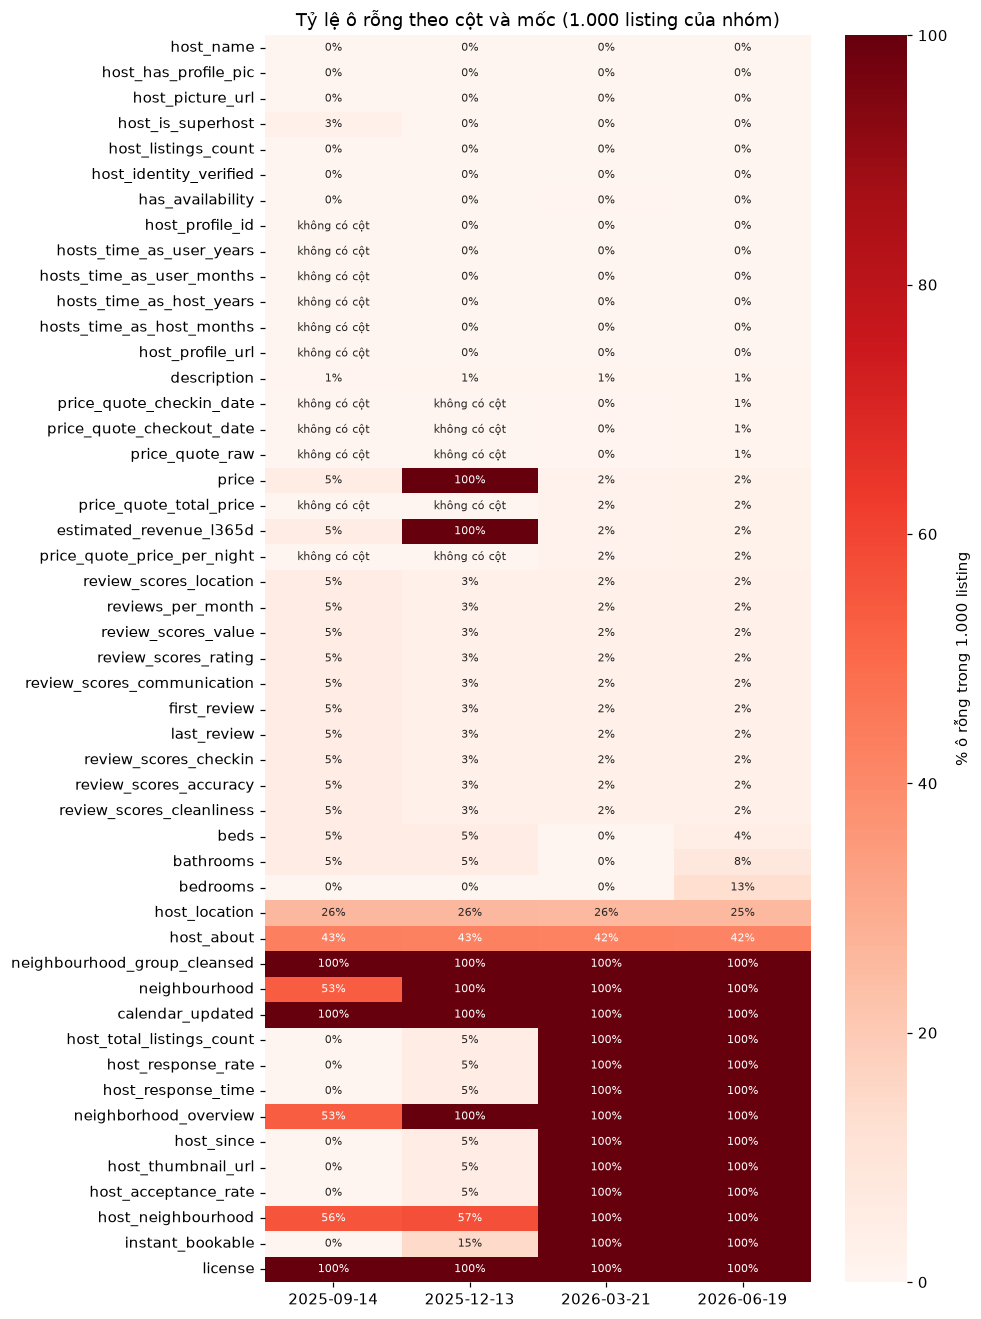

In [5]:
cac_cot = tat_ca_cot[1:]   # Bỏ "id" vì id đã là chỉ mục của bảng
co_cot = pd.DataFrame({s: [cot in listings_nhom[s].columns for cot in cac_cot] for s in snapshots}, index=cac_cot)

# eq("") so cả bảng một lần, mean() theo cột cho tỷ lệ ô rỗng (Bài 4).
# where(co_cot) giữ giá trị ở ô có cột, còn ô mà cột chưa tồn tại thành NaN (Bài 10).
ti_le_rong = pd.DataFrame({s: listings_nhom[s].reindex(columns=cac_cot).eq("").mean() * 100 for s in snapshots}).where(co_cot)
co_thieu = ti_le_rong.loc[ti_le_rong.fillna(0).gt(0).any(axis=1)].sort_values(moc_gia)

# Nhãn ghi trên từng ô: số phần trăm, hoặc "không có cột" khi cột chưa tồn tại ở mốc đó.
nhan = co_thieu.round(0).astype("Int64").astype("string").add("%").fillna("không có cột")

fig, ax = plt.subplots(figsize=(8, 0.28 * len(co_thieu) + 1))
sns.heatmap(
    co_thieu.fillna(0),
    annot=nhan.to_numpy(),
    fmt="",
    cmap="Reds",
    vmin=0,
    vmax=100,
    annot_kws={"fontsize": 7},
    cbar_kws={"label": "% ô rỗng trong 1.000 listing"},
    ax=ax,
)   # sns.heatmap tự ghi nhãn lên từng ô (Bài 13), không cần vòng lặp
ax.set(title="Tỷ lệ ô rỗng theo cột và mốc (1.000 listing của nhóm)", xlabel="", ylabel="")
ax.grid(False)
plt.show()

Biểu đồ nhiệt (heatmap) cho thấy các ô thiếu không cùng một nguyên nhân. Có thể chia chúng thành bốn kiểu, và mỗi kiểu cần một cách xử lý riêng.

Kiểu thứ nhất là cột rỗng ở mọi mốc: `neighbourhood_group_cleansed`, `calendar_updated` và `license`. Các cột này không có dữ liệu cho London,
nên không có gì để làm sạch. Điều cần nhớ chỉ là đừng dùng nhầm `neighbourhood_group_cleansed` thay cho `neighbourhood_cleansed`.

Kiểu thứ hai là cột có dữ liệu ở mốc đầu nhưng rỗng hoàn toàn từ một mốc trở đi. Cột `neighborhood_overview` rỗng toàn bộ từ mốc 2025-12-13.
Các cột `host_since`, `host_response_rate`, `host_response_time`, `host_acceptance_rate`, `host_total_listings_count`, `host_neighbourhood` và
`instant_bookable` rỗng toàn bộ từ mốc 2026-03-21. Các file chỉ cho thấy các trường này bị bỏ trống, không cho biết vì sao. Dù nguyên nhân là gì,
những cột như vậy không dùng được để so sánh theo thời gian. Cần lưu ý rằng không phải mọi cột về chủ nhà đều bị ảnh hưởng: `host_is_superhost`,
`host_identity_verified` hay `host_listings_count` vẫn có dữ liệu ở 999 trên 1.000 listing trong mỗi mốc năm 2026.

Kiểu thứ ba là thiếu có lý do. Nhóm cột `review_scores_*`, `first_review`, `last_review` và `reviews_per_month` thiếu đúng 50, 30, 25 và 25 dòng
ở bốn mốc. Ô dưới đây kiểm tra xem đó có phải chính những listing chưa có review nào hay không.

Kiểu thứ tư là thiếu mà dữ liệu không cho biết lý do, gồm `price` (53, 1.000, 17 và 20 ô rỗng) cùng `estimated_revenue_l365d`. Giá được bàn riêng ở mục 5.

In [6]:
# Vòng lặp qua từng mốc (4 lần), phép tính bên trong vẫn chạy trên cả cột.
for snapshot in snapshots:
    du_lieu = listings_nhom[snapshot]
    chua_co_review = du_lieu["number_of_reviews"].eq("0")
    thieu_diem = du_lieu["review_scores_rating"].eq("")
    thieu_gia = du_lieu["price"].eq("")
    thieu_doanh_thu = du_lieu["estimated_revenue_l365d"].eq("")
    print(f"{snapshot}: 0 review = {chua_co_review.sum():3d} | thiếu điểm = {thieu_diem.sum():3d} | "
          f"hai tập trùng nhau: {(chua_co_review == thieu_diem).all()} || "
          f"thiếu giá = {thieu_gia.sum():4d} | thiếu doanh thu ước tính trùng đúng tập thiếu giá: {(thieu_gia == thieu_doanh_thu).all()}")

2025-09-14: 0 review =  50 | thiếu điểm =  50 | hai tập trùng nhau: True || thiếu giá =   53 | thiếu doanh thu ước tính trùng đúng tập thiếu giá: True
2025-12-13: 0 review =  30 | thiếu điểm =  30 | hai tập trùng nhau: True || thiếu giá = 1000 | thiếu doanh thu ước tính trùng đúng tập thiếu giá: True
2026-03-21: 0 review =  25 | thiếu điểm =  25 | hai tập trùng nhau: True || thiếu giá =   17 | thiếu doanh thu ước tính trùng đúng tập thiếu giá: True
2026-06-19: 0 review =  25 | thiếu điểm =  25 | hai tập trùng nhau: True || thiếu giá =   20 | thiếu doanh thu ước tính trùng đúng tập thiếu giá: True


Ô trên thực hiện hai phép so khớp: Tập listing thiếu điểm review với tập listing có 0 review, và tập thiếu doanh thu ước tính với tập thiếu giá. Cả hai đều khớp hoàn toàn ở mọi mốc. Điểm review bị thiếu vì listing chưa có review nào. Nếu điền số 0 hay điểm trung bình vào đó,
ta sẽ tạo ra những đánh giá không có khách nào viết. Cách hợp lý là để trống và loại các listing này khỏi mẫu số khi tính điểm trung bình.

Còn `estimated_revenue_l365d` thiếu ở đúng những dòng thiếu giá. Điều này gợi ý rằng Inside Airbnb tính cột này từ giá nhân với số đêm
ước tính. Do đó, cột doanh thu ước tính cũng phải theo quy tắc giá của nhóm, tức là chỉ dùng ở mốc cuối. Ngay cả ở mốc cuối, nó vẫn chỉ là ước tính
của nguồn chứ không phải doanh thu thật của chủ nhà.

Ngoài ra còn một kiểu thiếu không hiện trên biểu đồ vì ô không rỗng. Cột `host_verifications` ghi chữ `"None"`, và bảng dưới cho thấy đây
cũng là một cột chỉ còn giá trị rỗng từ một mốc trở đi: Năm 2025 cột này có danh sách phương thức xác minh, nhưng từ năm 2026 cả 1.000 dòng chỉ còn chữ `"None"`.
Khi đọc bằng thiết lập mặc định, pandas coi chữ `"None"` là giá trị thiếu, nên số cột thiếu có thể chênh nhau một cột tùy cách đọc.
Báo cáo QA nên ghi rõ đang dùng quy ước nào.

In [7]:
pd.DataFrame({s: listings_nhom[s]["host_verifications"].value_counts().head(4) for s in snapshots}).fillna(0).astype(int)

,2025-09-14,2025-12-13,2026-03-21,2026-06-19
host_verifications,,,,
None,0,49,1000,1000
"['email', 'phone', 'work_email']",122,119,0,0
"['email', 'phone']",773,746,0,0
"['phone', 'work_email']",7,0,0,0
['phone'],96,81,0,0


## 4. Cách các giá trị được ghi trong file

File CSV không lưu kiểu dữ liệu, nên mọi giá trị đọc vào đều là chuỗi. Bảng dưới lấy vài ví dụ thật để thấy những cột trông như số
thực ra được ghi thế nào.

In [8]:
COT_MAU = ["price", "host_response_rate", "host_is_superhost", "bathrooms_text", "amenities", "last_scraped", "latitude"]
moc_dau = snapshots[0]
pd.DataFrame({cot: listings_nhom[moc_dau][cot].loc[listings_nhom[moc_dau][cot].ne("")].head(3).str[:60].tolist()
              for cot in COT_MAU}, index=["vi_du_1", "vi_du_2", "vi_du_3"]).T

,vi_du_1,vi_du_2,vi_du_3
price,$151.00,$178.00,$157.00
host_response_rate,100%,100%,67%
host_is_superhost,f,t,f
bathrooms_text,1.5 baths,1 bath,1 bath
amenities,"[""Self check-in"", ""Kitchen"", ""Smoke alarm"", ""Hair dryer"", ""S","[""Shared patio or balcony"", ""Kitchen"", ""Cleaning products"",","[""Kitchen"", ""Smoke alarm"", ""Private hot tub"", ""Shampoo"", ""Pa"
last_scraped,2025-09-15,2025-09-16,2025-09-16
latitude,51.52853,51.468505859375,51.52504


Mỗi cột cần một cách chuyển đổi riêng. Cột giá phải bỏ ký hiệu `$` và dấu phẩy ngăn cách hàng nghìn, còn cột tỷ lệ phải bỏ dấu `%`.
Các cờ ghi bằng `t` hoặc `f` cần đổi sang kiểu boolean. Cột `amenities` chứa cả một danh sách JSON trong một ô, còn `bathrooms_text` trộn số
với chữ, chẳng hạn "1.5 baths" hay "Shared half-bath".

Chi tiết dễ gây hiểu nhầm nhất là ký hiệu `$` trong cột `price`, trong khi London dùng bảng Anh và file cấu hình cũng ghi `GBP`. Ở mốc cuối có
cột `price_quote_raw` ghi rõ đơn vị tiền của báo giá, nên ta có thể đối chiếu trực tiếp.

In [9]:
du_lieu_cuoi = listings_nhom[moc_gia]
gia_niem_yet = pd.to_numeric(du_lieu_cuoi["price"].str.replace(r"[$,]", "", regex=True).replace("", np.nan))
gia_bao_gia = pd.to_numeric(du_lieu_cuoi["price_quote_price_per_night"].replace("", np.nan))

print("Đơn vị tiền trong price_quote_raw:",
      du_lieu_cuoi["price_quote_raw"].str.extract(r'"currency":\s*"(\w+)"')[0].value_counts().to_dict())
print("Số dòng price == price_quote_price_per_night:", int((gia_niem_yet == gia_bao_gia).sum()), "/", int(gia_niem_yet.notna().sum()))

Đơn vị tiền trong price_quote_raw: {'GBP': 980}
Số dòng price == price_quote_price_per_night: 980 / 980


Toàn bộ 980 báo giá đều ghi đơn vị `GBP`, và ở mọi dòng có giá, giá niêm yết đều bằng giá báo cho mỗi đêm. Vậy ký hiệu `$` chỉ là định dạng
chung mà Inside Airbnb dùng cho mọi thành phố. Khi làm sạch, ta chỉ cần bỏ ký tự đó và không quy đổi tỷ giá. Trong báo cáo, đơn vị của giá
nên được ghi là GBP.

## 5. Giá ở mốc cuối

Theo quy tắc của nhóm, giá chỉ được dùng ở mốc 2026-06-19. Không lấy giá của mốc này điền sang mốc khác, và không so sánh giá qua bốn mốc.
Bảng dưới cho thấy vì sao quy tắc này là cần thiết.

In [10]:
pd.DataFrame({
    s: {"o_gia_rong": int(listings_nhom[s]["price"].eq("").sum()),
        "o_gia_co_gia_tri": int(listings_nhom[s]["price"].ne("").sum())}
    for s in snapshots
}).T

,o_gia_rong,o_gia_co_gia_tri
2025-09-14,53,947
2025-12-13,1000,0
2026-03-21,17,983
2026-06-19,20,980


Ở mốc 2025-12-13, không listing nào của nhóm có giá. Nếu cố so sánh giá theo thời gian, ta sẽ không có số liệu nào ở một trong bốn mốc.
Từ đây trở xuống, notebook chỉ phân tích giá ở mốc cuối, với 980 listing có giá.

**Cách đọc biểu đồ.** Hình bên trái là biểu đồ tần suất (histogram). Mỗi cột gom các listing có giá rơi vào cùng một khoảng, và chiều cao cột là số listing trong khoảng đó. Trục ngang dùng thang log nên các vạch 100, 1.000 và 10.000 cách đều nhau dù mỗi vạch gấp mười lần vạch trước. Hệ quả là các cột trông rộng bằng nhau nhưng cột bên phải gom một khoảng giá rộng hơn nhiều so với cột bên trái.

Hình bên phải là biểu đồ hộp (boxplot), mỗi hộp ứng với một loại phòng. Vạch ngang trong hộp là trung vị. Đáy và nắp hộp là phân vị 25% và 75%, nên phần thân hộp chứa một nửa số listing nằm ở giữa. Râu kéo tới mức giá xa nhất còn nằm trong khoảng 1,5 lần IQR (hiệu giữa phân vị 75% và 25%) tính từ mép hộp, và mỗi vòng tròn rời bên ngoài râu là một listing có giá tách hẳn khỏi phần còn lại. Trục dọc cũng là thang log. Muốn biết hai loại phòng chênh giá bao nhiêu, cách nhanh nhất là so vạch trung vị của hai hộp.

count      980.0
mean       325.7
std        543.9
min         30.0
1%          45.6
5%          70.7
25%        150.0
50%        232.0
75%        363.7
95%        761.6
99%       1379.4
max      10000.0


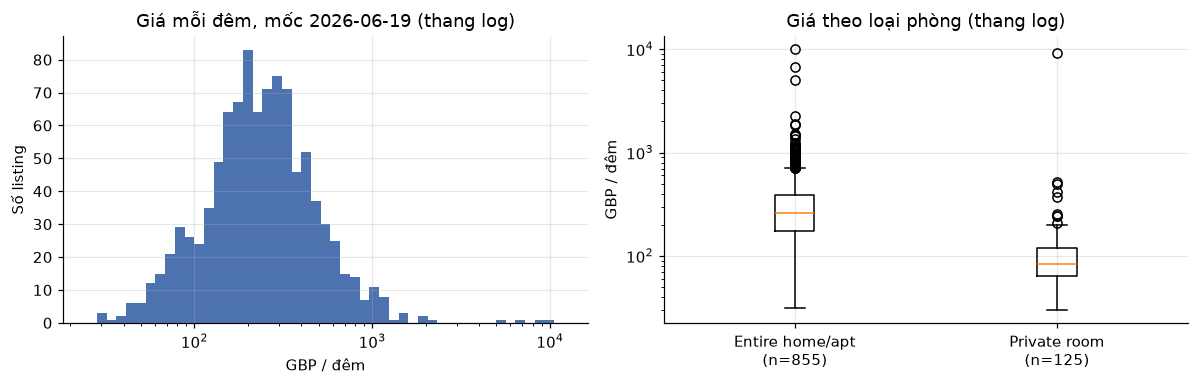

In [11]:
gia = gia_niem_yet.rename("price_gbp")
loai_phong = du_lieu_cuoi["room_type"]

print(gia.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(1).to_string())

fig, cac_truc = plt.subplots(1, 2, figsize=(11, 3.6))
cac_truc[0].hist(gia.dropna(), bins=np.logspace(np.log10(25), np.log10(12000), 50), color="#4C72B0")
cac_truc[0].set_xscale("log")
cac_truc[0].set_title(f"Giá mỗi đêm, mốc {moc_gia} (thang log)")
cac_truc[0].set_xlabel("GBP / đêm")
cac_truc[0].set_ylabel("Số listing")

nhom_loai = [gia[loai_phong.eq(loai)].dropna() for loai in ["Entire home/apt", "Private room"]]
cac_truc[1].boxplot(nhom_loai, tick_labels=[f"Entire home/apt\n(n={len(nhom_loai[0])})", f"Private room\n(n={len(nhom_loai[1])})"])
cac_truc[1].set_yscale("log")
cac_truc[1].set_title("Giá theo loại phòng (thang log)")
cac_truc[1].set_ylabel("GBP / đêm")
plt.tight_layout()
plt.show()

Giá trải từ khoảng 30 tới 10.000 GBP mỗi đêm, tức chênh nhau hơn ba trăm lần. Phân bố lệch phải mạnh, thể hiện ở chỗ giá trung bình
(khoảng 326) cao hơn hẳn trung vị (khoảng 232). Vì vậy KPI về giá nên dùng trung vị, và biểu đồ giá nên dùng thang logarit (thang log), tức là chia trục theo bội số thay vì theo khoảng cộng. Trên thang này,
khoảng cách từ 100 đến 1.000 bằng khoảng cách từ 1.000 đến 10.000, nhờ đó phần lớn listing không bị dồn vào một góc.

Hai loại phòng có mức giá rất khác nhau: Trung vị của nguyên căn khoảng 258 GBP, còn của phòng riêng khoảng 83 GBP. Khi so sánh giá giữa
các khu vực, cần tách theo loại phòng hoặc chuẩn hóa theo loại phòng. Nếu không, một quận có nhiều phòng riêng sẽ trông rẻ chỉ vì cơ cấu
loại phòng của nó, chứ chưa chắc vì giá ở đó thấp hơn.

Câu hỏi tiếp theo của QA là đặt ngưỡng nào để gọi một mức giá là ngoại lai.

In [12]:
NGUONG_CAU_HINH = cau_hinh["qa"]["price_max_gbp"]
q1, q3 = gia.quantile([0.25, 0.75])
nguong_iqr_log = float(np.exp(np.log(q3) + 1.5 * (np.log(q3) - np.log(q1))))

so_sanh_nguong = pd.DataFrame({
    "nguong_GBP": {"Config hiện tại (qa.price_max_gbp)": NGUONG_CAU_HINH, "Ví dụ 5.000": 5000,
                   "Ví dụ 2.000": 2000, "IQR trên log(giá)": round(nguong_iqr_log)},
})
so_sanh_nguong["so_listing_vuot"] = [int((gia > nguong).sum()) for nguong in so_sanh_nguong["nguong_GBP"]]
display(so_sanh_nguong)

print("10 giá cao nhất:", gia.nlargest(10).round(0).tolist())
du_lieu_cuoi.loc[gia.nlargest(5).index, ["room_type", "property_type", "accommodates", "bedrooms", "price", "minimum_nights", "number_of_reviews"]]

,nguong_GBP,so_listing_vuot
Config hiện tại (qa.price_max_gbp),5000000,0
Ví dụ 5.000,5000,4
Ví dụ 2.000,2000,5
IQR trên log(giá),1374,10


10 giá cao nhất: [10000.0, 9130.0, 6762.0, 5044.0, 2252.0, 1870.0, 1847.0, 1504.0, 1482.0, 1460.0]


,room_type,property_type,accommodates,bedrooms,price,minimum_nights,number_of_reviews
id,,,,,,,
994242543616842898,Entire home/apt,Entire rental unit,4,2,"$10,000.00",4,38
9470827,Private room,Private room in rental unit,1,,"$9,129.50",2,8
817983420141077409,Entire home/apt,Entire rental unit,6,2,"$6,762.50",2,26
936687180775858720,Entire home/apt,Entire rental unit,2,1,"$5,044.50",2,18
4333071,Entire home/apt,Entire home,5,3,"$2,251.80",5,5


Ngưỡng `price_max_gbp: 5000000` đang có trong config sẽ không bao giờ bắt được dòng nào, vì nó lớn hơn giá cao nhất tới năm trăm lần.
Quy tắc IQR cho một ngưỡng có căn cứ hơn. IQR (khoảng tứ phân vị) là hiệu giữa phân vị 75% và phân vị 25%, tức độ rộng của nửa giữa dữ liệu. Quy tắc này coi những giá trị
vượt quá phân vị 75% thêm 1,5 lần IQR là bất thường. Vì giá lệch phải mạnh, ta tính IQR trên log(giá) thay vì trên giá gốc. Ngưỡng thu được khoảng 1.400 GBP, và có 10 listing vượt ngưỡng này.

Năm dòng đắt nhất cho thấy vì sao nên gắn cờ những giá này. Không dòng nào là biệt thự lớn. Mức 10.000 GBP mỗi đêm thuộc về một căn hộ
hai phòng ngủ cho bốn khách, còn hơn 9.000 GBP mỗi đêm là giá của một phòng riêng cho một người. Dữ liệu không cho biết vì sao các mức giá này cao như vậy,
nhưng chúng không ăn khớp với loại phòng và sức chứa của chính listing đó. Sau bốn mức giá trên 5.000 là
một khoảng hở lớn, từ 5.044 tụt thẳng xuống 2.252, nên nhóm giá cực đoan này tách hẳn khỏi phần còn lại.

Đề xuất của người khảo sát là dùng ngưỡng để gắn cờ chứ không xóa dòng. Sau đó tính KPI giá hai lần, có và không có các dòng bị gắn cờ,
rồi ghi chênh lệch vào `qa_report.csv` như đề yêu cầu. Giá trị cụ thể của ngưỡng do nhóm chốt.

## 6. Các cột phân loại

In [13]:
pd.DataFrame({
    "thanh_pho": listings_thanh_pho[moc_gia]["room_type"].value_counts(),
    "nhom_15": du_lieu_cuoi["room_type"].value_counts(),
}).fillna(0).astype(int).assign(**{
    "%_thanh_pho": lambda b: (100 * b["thanh_pho"] / b["thanh_pho"].sum()).round(1),
    "%_nhom": lambda b: (100 * b["nhom_15"] / b["nhom_15"].sum()).round(1),
})

,thanh_pho,nhom_15,%_thanh_pho,%_nhom
room_type,,,,
Entire home/apt,61377,875,66.3,87.5
Hotel room,180,0,0.2,0.0
Private room,30878,125,33.3,12.5
Shared room,203,0,0.2,0.0


Toàn thành phố có bốn loại phòng, nhưng mẫu của nhóm chỉ có hai loại: 875 nguyên căn (Entire home/apt) và 125 phòng riêng (Private room).
Tỷ lệ này giữ nguyên ở cả bốn mốc và khác hẳn tỷ lệ của thị trường, vốn vào khoảng 66% và 33%. Mẫu đã được chọn theo một cơ cấu định sẵn.
Vì thế, một câu như "87% chỗ ở tại London là nguyên căn" sẽ sai, bởi con số đó phản ánh cách chọn mẫu chứ không phải thị trường.

**Cách đọc biểu đồ.** Mỗi thanh là một quận, chiều dài thanh là số listing của nhóm nằm trong quận đó. Các quận được xếp từ nhiều listing nhất ở trên cùng tới ít nhất ở dưới cùng. Thanh màu đỏ đánh dấu những quận có dưới 10 listing, cũng là cỡ mẫu tối thiểu mà config đặt cho KPI (`kpi.min_n`). Phần cần nhìn kỹ là đáy biểu đồ, vì KPI tính cho các quận ở đó sẽ dựa trên rất ít listing.

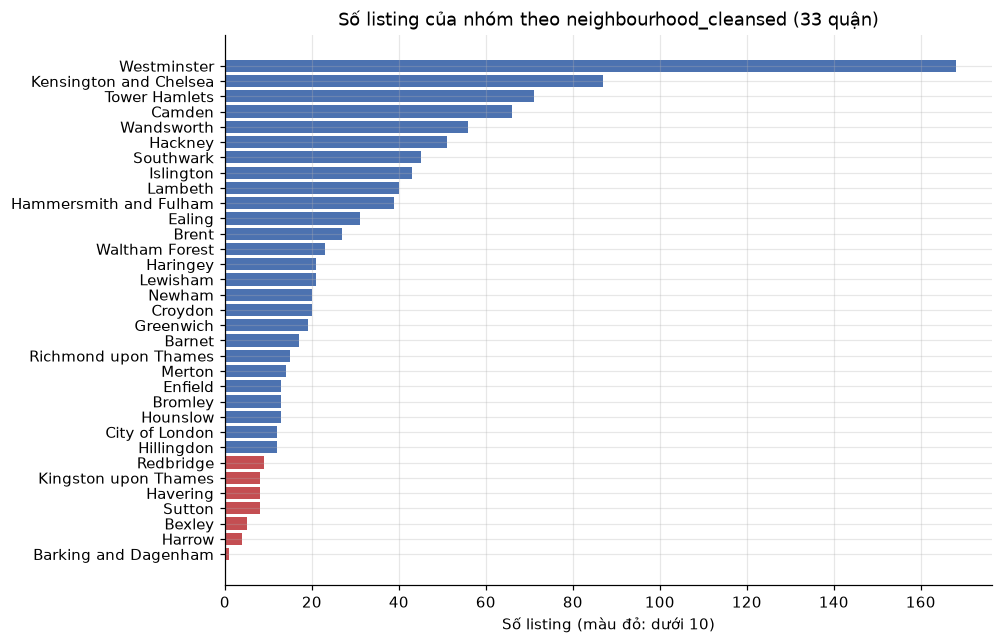

Quận có dưới 10 listing: {'Redbridge': 9, 'Kingston upon Thames': 8, 'Havering': 8, 'Sutton': 8, 'Bexley': 5, 'Harrow': 4, 'Barking and Dagenham': 1}
Property type phổ biến: {'Entire rental unit': 508, 'Entire home': 138, 'Entire condo': 134, 'Entire serviced apartment': 57, 'Private room in home': 47, 'Private room in rental unit': 32}


In [14]:
khu_vuc = du_lieu_cuoi["neighbourhood_cleansed"].value_counts()

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(khu_vuc.index[::-1], khu_vuc.values[::-1], color=np.where(khu_vuc.values[::-1] < 10, "#C44E52", "#4C72B0"))
ax.set_title(f"Số listing của nhóm theo neighbourhood_cleansed ({khu_vuc.size} quận)")
ax.set_xlabel("Số listing (màu đỏ: dưới 10)")
plt.show()

print("Quận có dưới 10 listing:", khu_vuc[khu_vuc < 10].to_dict())
print("Property type phổ biến:", du_lieu_cuoi["property_type"].value_counts().head(6).to_dict())

Mẫu có mặt ở đủ 33 quận, nhưng phân bố rất không đều. Westminster có 168 listing, trong khi Barking and Dagenham chỉ có 1 và Harrow có 4.
Một trung vị giá hay một tỷ lệ tính trên dưới mười listing có thể dao động mạnh chỉ vì cỡ mẫu nhỏ. Khi trình bày
KPI theo quận, nhóm nên luôn ghi kèm số listing `n`, và cân nhắc gộp các quận có dưới 10 listing hoặc chỉ xếp hạng những quận đủ cỡ mẫu.

## 7. Các cột hoạt động: Review, ngày sẵn có và số đêm tối thiểu

In [15]:
COT_SO = ["number_of_reviews", "number_of_reviews_ltm", "review_scores_rating", "availability_365", "minimum_nights",
          "estimated_occupancy_l365d", "accommodates"]

def doi_sang_so(du_lieu: pd.DataFrame, cac_cot: list[str]) -> pd.DataFrame:
    """Đổi các cột chuỗi sang số; ô rỗng thành NA, chuỗi lạ sẽ báo lỗi thay vì bị âm thầm bỏ qua."""
    # apply theo CỘT (7 lần gọi pd.to_numeric), không phải theo hàng, vì pd.to_numeric chỉ nhận một Series.
    return du_lieu[cac_cot].replace("", np.nan).apply(pd.to_numeric, errors="raise")

so_lieu = {s: doi_sang_so(listings_nhom[s], COT_SO) for s in snapshots}
pd.concat({s: so_lieu[s].median() for s in snapshots}, axis=1).round(2)

,2025-09-14,2025-12-13,2026-03-21,2026-06-19
number_of_reviews,13.00,16.00,18.0,20.00
number_of_reviews_ltm,5.00,6.00,6.0,6.00
review_scores_rating,4.82,4.81,4.8,4.79
availability_365,243.00,254.00,235.0,243.00
minimum_nights,2.00,2.00,2.0,2.00
estimated_occupancy_l365d,46.00,55.00,55.0,55.00
accommodates,4.00,4.00,4.0,4.00


**Cách đọc biểu đồ.** Cả ba hình con đều tính trên 1.000 listing ở mốc cuối, và trục dọc của cả ba là số listing.

Hai hình đầu là biểu đồ tần suất. Ở hình điểm review, trục ngang chạy từ 1 đến 5 và mỗi cột rộng 0,1 điểm, nên một cột cao vọt ở sát mép phải nghĩa là rất nhiều listing có điểm gần tuyệt đối. Ở hình `availability_365`, mỗi cột gom khoảng mười ngày, từ 0 ngày ở bên trái tới 365 ngày ở bên phải.

Hình thứ ba là biểu đồ cột thường. Mỗi cột là một giá trị `minimum_nights` có xuất hiện trong dữ liệu, và các cột được đặt cách đều nhau bất kể giá trị. Vì vậy khoảng cách giữa hai cột không phản ánh khoảng cách giữa hai giá trị: Cột 7 đứng ngay cạnh cột 12, dù ở giữa còn bốn mức không listing nào dùng. Muốn biết một cột ứng với bao nhiêu đêm thì đọc nhãn dưới cột.

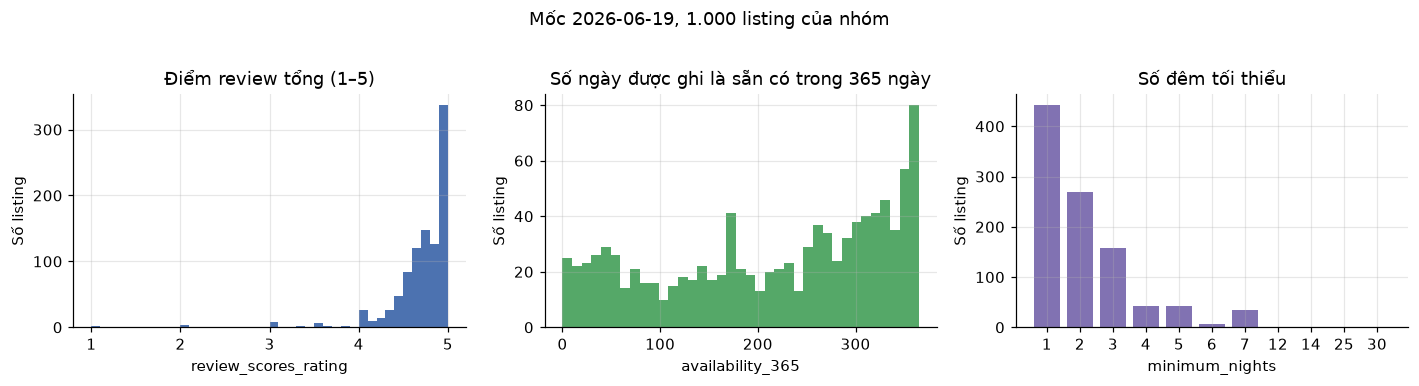

In [16]:
fig, cac_truc = plt.subplots(1, 3, figsize=(13, 3.4))
cac_truc[0].hist(so_lieu[moc_gia]["review_scores_rating"].dropna(), bins=40, color="#4C72B0")
cac_truc[0].set_title("Điểm review tổng (1–5)")
cac_truc[0].set_xlabel("review_scores_rating")
cac_truc[1].hist(so_lieu[moc_gia]["availability_365"], bins=37, color="#55A868")
cac_truc[1].set_title("Số ngày được ghi là sẵn có trong 365 ngày")
cac_truc[1].set_xlabel("availability_365")
dem_toi_thieu = so_lieu[moc_gia]["minimum_nights"].value_counts().sort_index()
cac_truc[2].bar(dem_toi_thieu.index.astype(str), dem_toi_thieu.values, color="#8172B2")
cac_truc[2].set_title("Số đêm tối thiểu")
cac_truc[2].set_xlabel("minimum_nights")
for ax in cac_truc:   # Ba trục của ba biểu đồ con, không phải dòng dữ liệu
    ax.set_ylabel("Số listing")
fig.suptitle(f"Mốc {moc_gia}, 1.000 listing của nhóm", y=1.02)
plt.tight_layout()
plt.show()

Biểu đồ đầu tiên cho thấy điểm review dồn sát mức tối đa. Trung vị khoảng 4,8 trên 5, và khoảng ba phần tư số listing nằm trong khoảng
4,6 đến 5,0. Trong một phân bố hẹp như vậy, chênh lệch 0,1 điểm giữa hai quận nghe nhỏ nhưng đã là một khoảng đáng kể so với độ rộng của cả phân bố. Tuy vậy, vì mọi listing đều dồn gần mức tối đa, điểm số gần như
không phân biệt được trải nghiệm tốt với trải nghiệm rất tốt. Phân tích nội dung review bằng LLM có thể bù vào chỗ thiếu này, vì nó đọc
được những lời chê mà điểm trung bình đã làm mờ đi.

Biểu đồ thứ hai cho thấy `availability_365` trải đủ mọi mức, từ những listing gần như không có ngày nào được ghi là sẵn có tới những listing
sẵn có gần trọn năm. Một ngày không sẵn có chưa chắc là ngày đã có khách đặt. Notebook 03 sẽ xem lại điểm này bằng dữ liệu lịch.

Biểu đồ thứ ba cho thấy gần như không có chỗ cho thuê dài hạn. Phần lớn listing chỉ yêu cầu từ một đến ba đêm, và chỉ lác đác vài listing
đặt mức từ 12 đêm trở lên. Mẫu này vì thế phản ánh thị trường lưu trú ngắn ngày, cũng là mảng mà hiệp hội du lịch quan tâm.

## 8. Những gì thay đổi ở cùng một listing qua các mốc

Vì 1.000 listing được giữ cố định, ta có thể so từng cột của cùng một chỗ ở giữa mốc đầu và mốc cuối.

In [17]:
dau, cuoi = listings_nhom[snapshots[0]], listings_nhom[moc_gia].loc[listings_nhom[snapshots[0]].index]
COT_SO_SANH = ["room_type", "neighbourhood_cleansed", "host_id", "property_type", "accommodates", "latitude", "longitude",
               "name", "minimum_nights", "maximum_nights", "number_of_reviews"]
pd.Series({cot: int(dau[cot].ne(cuoi[cot]).sum()) for cot in COT_SO_SANH},
          name=f"số listing đổi giá trị {snapshots[0]} → {moc_gia}").to_frame()

,số listing đổi giá trị 2025-09-14 → 2026-06-19
room_type,0
neighbourhood_cleansed,0
host_id,4
property_type,19
accommodates,55
latitude,26
longitude,26
name,181
minimum_nights,344
maximum_nights,294


Những cột mô tả bản thân chỗ ở gần như không đổi. Không listing nào đổi loại phòng hay đổi quận, và chỉ 4 listing đổi chủ. Ngược lại,
những gì chủ nhà có thể tự chỉnh thì thay đổi nhiều: 181 listing đổi tên quảng cáo, 344 listing có số đêm tối thiểu ở mốc cuối khác mốc đầu.
Nếu xét cả bốn mốc, ô dưới cho thấy 396 listing đổi số đêm tối thiểu ít nhất một lần. Cột
`number_of_reviews` thay đổi ở 745 listing, đúng như kỳ vọng với một biến cộng dồn.

Ô dưới đây xem kỹ hai chi tiết nhỏ mà QA nên biết.

In [18]:
so_review = pd.DataFrame({s: pd.to_numeric(listings_nhom[s]["number_of_reviews"]) for s in snapshots})
# Vòng lặp qua 3 cặp mốc liền nhau; so sánh bên trong chạy trên cả cột.
for truoc, sau in zip(snapshots, snapshots[1:]):
    giam = so_review.index[so_review[sau] < so_review[truoc]]
    print(f"number_of_reviews giảm {truoc} → {sau}: {len(giam)} listing", so_review.loc[giam, [truoc, sau]].to_dict("index"))

dem_toi_thieu = pd.DataFrame({s: listings_nhom[s]["minimum_nights"] for s in snapshots})
print("Listing đổi minimum_nights ít nhất một lần qua bốn mốc:", int(dem_toi_thieu.nunique(axis=1).gt(1).sum()))   # nunique theo hàng (Bài 5)

# Khoảng cách giữa tọa độ mốc đầu và mốc cuối, quy đổi độ sang km bằng phép xấp xỉ mặt phẳng:
# 1 độ vĩ ≈ 111,32 km, còn 1 độ kinh ≈ 111,32 × cos(vĩ độ) km.
vi_do_dau, vi_do_cuoi = pd.to_numeric(dau["latitude"]), pd.to_numeric(cuoi["latitude"])
kinh_do_dau, kinh_do_cuoi = pd.to_numeric(dau["longitude"]), pd.to_numeric(cuoi["longitude"])
lech_bac_nam_km = (vi_do_cuoi - vi_do_dau) * 111.32
lech_dong_tay_km = (kinh_do_cuoi - kinh_do_dau) * 111.32 * np.cos(np.radians((vi_do_dau + vi_do_cuoi) / 2))
khoang_cach_km = np.sqrt(lech_bac_nam_km**2 + lech_dong_tay_km**2)
print(f"Tọa độ thay đổi ở {int(khoang_cach_km.gt(0).sum())} listing, khoảng cách lớn nhất khoảng {khoang_cach_km.max():.2f} km")

number_of_reviews giảm 2025-09-14 → 2025-12-13: 1 listing {'1352468099589735817': {'2025-09-14': 3, '2025-12-13': 2}}
number_of_reviews giảm 2025-12-13 → 2026-03-21: 1 listing {'17818925': {'2025-12-13': 222, '2026-03-21': 221}}
number_of_reviews giảm 2026-03-21 → 2026-06-19: 0 listing {}
Listing đổi minimum_nights ít nhất một lần qua bốn mốc: 396
Tọa độ thay đổi ở 26 listing, khoảng cách lớn nhất khoảng 1.32 km


Một biến cộng dồn như số review lẽ ra chỉ tăng hoặc giữ nguyên, nhưng hai listing có số review giảm đi một. Dữ liệu không cho biết vì sao.
Không cần sửa giá trị này, nhưng nên gắn cờ để người đọc báo cáo biết.

Tọa độ của 26 listing thay đổi giữa mốc đầu và mốc cuối, xa nhất khoảng 1,3 km. Theo mô tả dữ liệu của Inside Airbnb, tọa độ của listing đã được
làm mờ để không lộ địa chỉ chính xác, nhưng các file không cho biết vì sao tọa độ của cùng một listing lại thay đổi giữa các lần chụp. Điều chắc chắn
là vùng tính lại từ tọa độ có thể khác nhau giữa các mốc. Cột `analysis_area` trong file phân công là cố định và nên được dùng nguyên như vậy.
Notebook 05 chỉ ra hai listing mà tọa độ ở mốc đầu nằm ngoài hình chữ nhật của chính vùng được giao.

## 9. Ngày thu thập thật của từng listing

Tên thư mục là ngày chụp, nhưng mỗi listing được cào vào một ngày cụ thể, ghi trong cột `last_scraped`. Bảng dưới đo khoảng cách giữa hai
ngày này, tính bằng số ngày.

In [19]:
tre = pd.DataFrame({
    s: (pd.to_datetime(listings_nhom[s]["last_scraped"]) - pd.Timestamp(s)).dt.days.describe()[["min", "50%", "max"]]
    for s in snapshots
}).T.rename(columns={"min": "sớm_nhất", "50%": "trung_vị", "max": "muộn_nhất"})
tre["listing_lay_tu_lan_cao_truoc"] = [int(listings_nhom[s]["source"].eq("previous scrape").sum()) for s in snapshots]
tre

,sớm_nhất,trung_vị,muộn_nhất,listing_lay_tu_lan_cao_truoc
2025-09-14,0.0,1.0,4.0,52
2025-12-13,0.0,2.0,20.0,52
2026-03-21,0.0,6.0,12.0,0
2026-06-19,0.0,7.0,12.0,29


Độ trễ lớn nhất ở bốn mốc lần lượt là 4, 20, 12 và 12 ngày. Ở mốc 2025-12-13, có listing được cào sang tận đầu năm 2026, còn hai mốc năm 2026
có độ trễ trung vị khoảng một tuần. Vì vậy, "mốc chụp" thực chất là một khoảng vài ngày đến vài tuần chứ không phải một ngày duy nhất, và báo cáo nên mô tả
đúng như thế.

Cột cuối đếm các listing có `source` là `previous scrape`, lần lượt 52, 52, 0 và 29 dòng. Theo tên nhãn, dữ liệu của những dòng này lấy từ một
lần cào trước, nên các trường như giá hay số ngày sẵn có có thể không phản ánh đúng thời điểm chụp. Vì vậy, cột `source` nên được đưa vào QA thành một cờ, báo rằng dòng đó mang dữ liệu kế thừa từ lần cào trước.

## 10. Thử gắn cờ trên bảng 4.000 dòng

Ô cuối gom các quan sát ở trên thành những cột cờ kiểu boolean, trên bảng gồm 1.000 listing nhân 4 mốc. Đây là bản minh họa cho cách làm
"gắn cờ, không xóa" mà đề yêu cầu. Tên cờ và ngưỡng là đề xuất, chưa phải quy tắc QA chính thức của nhóm.

In [20]:
cac_bang = []
# Vòng lặp qua từng mốc (4 lần), phép tính bên trong vẫn chạy trên cả cột.
for snapshot in snapshots:
    du_lieu = listings_nhom[snapshot]
    gia_so = pd.to_numeric(du_lieu["price"].str.replace(r"[$,]", "", regex=True).replace("", np.nan))
    co = pd.DataFrame(index=du_lieu.index)
    co["snapshot_date"] = snapshot
    co["flag_thieu_gia_moc_cuoi"] = (snapshot == moc_gia) & gia_so.isna()
    co["flag_gia_ngoai_lai"] = (snapshot == moc_gia) & (gia_so > nguong_iqr_log)
    co["flag_chua_co_review"] = du_lieu["number_of_reviews"].eq("0")
    co["flag_365_ngay_khong_san_co"] = du_lieu["availability_365"].eq("0")
    co["flag_du_lieu_ke_thua"] = du_lieu["source"].eq("previous scrape")
    co["flag_cot_host_bi_tat"] = du_lieu["host_response_rate"].eq("").all()
    cac_bang.append(co)

bang_co = pd.concat(cac_bang)
bang_co.groupby("snapshot_date").sum(numeric_only=True).T

snapshot_date,2025-09-14,2025-12-13,2026-03-21,2026-06-19
flag_thieu_gia_moc_cuoi,0,0,0,20
flag_gia_ngoai_lai,0,0,0,10
flag_chua_co_review,50,30,25,25
flag_365_ngay_khong_san_co,21,23,4,6
flag_du_lieu_ke_thua,52,52,0,29
flag_cot_host_bi_tat,0,0,1000,1000


Bảng cờ cho biết mỗi mốc có vấn đề ở đâu và lớn tới mức nào. Đọc theo hàng, số listing chưa có review giảm dần từ 50 xuống 25, vì review
tích lũy theo thời gian. Số listing mà cả 365 ngày đều không sẵn có giảm mạnh, từ 21 và 23 ở năm 2025 xuống 4 và 6 ở năm 2026. Cờ
`flag_cot_host_bi_tat` bật ở toàn bộ 1.000 dòng của hai mốc năm 2026, nhắc rằng các KPI dựa trên `host_response_rate` và các cột rỗng tương tự
chỉ tính được ở hai mốc năm 2025. Các cột chủ nhà còn dữ liệu, như `host_is_superhost`, vẫn dùng được ở cả bốn mốc.

Notebook 06 sẽ gom cờ của cả bốn bảng lại. Trước đó, notebook 03 xem bảng calendar để hiểu các con số về ngày sẵn có vừa gặp ở mục 7.